# Project overview - Exercise 1, Reservoir Geological Characterization

**Goal.** Solve the image-analysis exercise of page 3 of `Exerc1_GeoRes_2026.pdf` in Python, as a real image
processing and analysis problem, on the two thin-section images `Lamina_alunos2.png` (small) and
`Lamina_alunos_grande.png` (large). The pores are impregnated with blue epoxy.

**How the project is solved.** Five notebooks, each building on the previous one:

1. **01 - Three-phase segmentation:** every pixel is classified as grain, pore or cement using the CIELAB color space
   (brightness separates grains; color hue separates blue pores from brown cement).
2. **02 - Objects:** the grain and pore areas are split into individual grains and pore bodies (watershed on the
   distance to the edge + neck-ratio merge).
3. **03 - Areas and sizes:** area, size distribution, sorting, pore throats and shape of every object.
4. **04 - Heterogeneity:** how uniform the pore/grain distribution is, and how large a sample must be (REV).
5. **05 - Fourier shape analysis:** grain outlines described by radii r(theta) and their Fourier harmonics.

**Where each task is solved.** Page 3 lists 8 tasks; page 4 marks tasks 1-3 as done in class and tasks 4-8 as the
**Challenge (C1-C5)**. This project solves tasks 1-7 (C1-C4). Each notebook title names the task(s) it solves.

| Page 3 task | Challenge | Topic | Where it is solved | Key outputs (`outputs/`) | Main result |
|---|---|---|---|---|---|
| **1** | (class) | Porosity, grains and cement: volume calculation | this notebook §2 (rules), **§3 (fractions)**, §4 (sensitivity); [03](03_areas_and_size_distributions.ipynb) §2 | `phases_*.npy/png`, `01_phase_fractions.csv`, `01_porosity_sensitivity.csv`, `03_phase_areas.csv` | grain 57.8 %, pore 19.0 %, cement 23.2 % (small image); porosity ~ 19 %, range ~ 16-19 % for chroma limits 5-8 |
| **2** | (class) | Representative volume of porosity (REV) | [04](04_heterogeneity.ipynb) **§1 (REV)**, §3 (integral range) | `04_rev_random_windows.csv`, `04_rev_sizes.csv`, `04_integral_range.csv` | porosity REV ~ 360 Lpx (+-20 %) and ~ 800 Lpx (+-10 %) |
| **3** | (class) | Grain segmentation | [02](02_pore_and_grain_objects.ipynb) §1, **§3 (separated grains)**, before/after merge, zoomed check | `labels_grain_*.npy`, `02_objects.csv` | 803 grains (small), 3,739 (large) |
| **4** | **C1** | Heterogeneity in the distribution of pores or grains | [04](04_heterogeneity.ipynb) §2 (correlation), §4 (lacunarity), §5 (point patterns), §6 (maps), §7 (block data mining) | `04_*.csv`, `04_porosity_map_128.npy` | pores cluster in patches ~ 150-250 Lpx; local porosity is controlled by cement, not texture |
| **5** | **C2** | Porous segmentation | [02](02_pore_and_grain_objects.ipynb) §1, **§2 (pore bodies)**, §4 (PoreSpy SNOW cross-check) | `labels_pore_*.npy`, `02_object_counts.csv` | 406 pore bodies (small), 1,751 (large) |
| **6** | **C3** | Area of the segmented pores and grains | [03](03_areas_and_size_distributions.ipynb) §1 (image scale), **§3 (size distributions, Folk & Ward)**, §4 (throats), §5 (shape) | `03_objects_scaled.csv`, `03_folk_ward.csv`, `03_throats.csv`, `03_registration.csv` | grain D50 ~ 13.8 Lpx, moderately well sorted; largest 10 % of pores hold 38 % of the pore area |
| **7** | **C4** | Data for Fourier analysis | [05](05_fourier_grain_shape.ipynb) **§2 (radial signatures r(theta))**, §3 (resolution test), §4-8 (spectra, shape space, fabric) | `05_radial_signatures.csv`, `05_harmonic_amplitudes.csv`, `05_efd_coefficients.csv`, `05_grain_shape.csv` | 760 grains x 64 radii; harmonics 2-14 reliable; one shape population |

**Supporting code**

| Folder | Content |
|---|---|
| `src/` | shared modules: `segmentation.py` (tasks 1, 3, 5), `objects.py` (3, 5, 6), `sizestats.py` (6), `heterogeneity.py` (2, 4), `shape.py` (7) |
| `scripts/` | explanatory figures used in notebooks 01-02 (CIELAB, sigma, Otsu, pore rule, clean-up, split steps, merge check, h and neck ratio), saved to `outputs/figures/` |

**How to run.** Execute the notebooks in order 01 -> 05 (each reads the outputs of the previous ones), then the
scripts in `scripts/` if the explanatory figures need to be regenerated. Sizes are in pixels (no scale bar was
given); notebook 03 shows how to convert them once the pixel size is known.

---

# 01 - Three-phase segmentation: grain / pore / cement (Task 1)

**Exercise 1 - Reservoir Geological Characterization**

Base step for all challenge tasks. Thin section impregnated with **blue epoxy**:

| Phase | Appearance | Color signature |
|---|---|---|
| Grain (quartz/feldspar) | white / cream | high L*, neutral |
| Pore | blue epoxy | Lab hue ~ -80 deg, chroma > 0 |
| Cement / matrix / opaques | dark brown / black | low L*, neutral or brown hue (~ +40 deg) |

The class notebook worked in **grayscale**, where pore (dark blue) and cement (dark brown) share the same gray level,
so it could only separate *grain vs. non-grain*. Here we use the **CIE Lab** color space so the three phases can be separated.

Scale: no scale bar is given, so results are in **pixels** and **area fractions** (2D area fraction = volume fraction by the Delesse principle).

**Structure of this notebook**
0. The input images.
1. Why grayscale is not enough: the color space used instead (CIELAB).
2. The segmentation rules: how each pixel is classified, how each value was chosen, and a visual check.
3. Phase fractions (Task 1): porosity, grain and cement volume.
4. Sensitivity: how much porosity depends on the pore rule.
5. Save the phase maps for notebooks 02-05.

In [1]:
import sys
sys.path.insert(0, '../src')
import figstyle; figstyle.install()   # larger text in all figures
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from skimage import color, filters
from segmentation import load_rgb, to_lab, three_phase, phase_rgb, phase_fractions, GRAIN, PORE, CEMENT

plt.rcParams['figure.dpi'] = 90
IMAGES = {'small': '../Lamina_alunos2.png', 'large': '../Lamina_alunos_grande.png'}
imgs = {k: load_rgb(p) for k, p in IMAGES.items()}
for k, im in imgs.items():
    print(f'{k:6s} shape={im.shape}')

small  shape=(569, 855, 3)
large  shape=(1061, 1482, 3)


## 0. The input images

**Why it matters.** This section **shows the raw data** everything else is measured on. It is useful because:

1. **It shows what has to be measured**: grains (white), pores (blue epoxy) and cement (dark).
2. **It shows the difficulty**: pores and cement are both dark; some pores are very dark blue.
3. **It introduces both images** (small and large), used together throughout the project.

**What.** The two thin-section photos (loaded in the cell above as `imgs['small']` and `imgs['large']`).

**Reading them.** White/cream = grains (quartz, feldspar); blue = pores filled with blue epoxy; dark brown/black =
cement, matrix and opaque minerals. The small image is a zoomed-in part of the large one (shown in notebook 03).

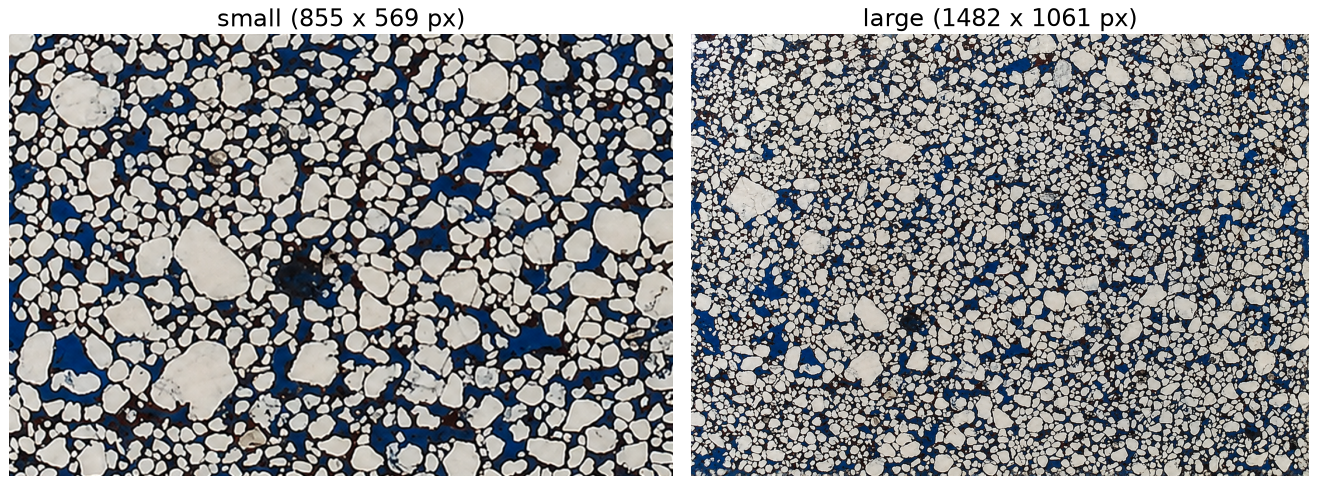

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for a, (k, im) in zip(ax, imgs.items()):
    a.imshow(im); a.set_title(f'{k} ({im.shape[1]} x {im.shape[0]} px)'); a.axis('off')
plt.tight_layout(); plt.show()

## 1. Why grayscale is not enough

**The question.** To measure porosity, grain and cement volume we must decide, for every pixel, which of the three phases it
belongs to. The class method used a grayscale image, i.e. only brightness.

**Why it matters.** This section shows **why the class method cannot separate pores from cement, and which color space can**. It is useful because:

1. **It explains the main problem of the segmentation.** In grayscale, pore and cement have the same brightness, so only grain vs the rest can be separated; porosity cannot be measured.
2. **It introduces the solution (CIELAB)**, which separates brightness from color: brightness finds grains, color (hue) separates blue pores from brown cement.
3. **It shows where each phase lies in color space**, which is the evidence for every rule of section 2.

**The problem.** The grayscale histogram is **bimodal** (dark ~ 20-50 and bright ~ 210-230): there are only two populations,
but the image has three phases. Pore and cement collapse into the dark peak.

**What we do instead.** We describe each pixel's color in the **CIELAB** color space, which separates brightness
from color. Brightness then separates grains, and color separates blue pores from brown cement. The next cells
explain CIELAB and show where the three phases fall in it (figure below).

### The CIELAB (L\*a\*b\*) color space in brief

CIELAB describes each pixel with three numbers instead of R, G, B:

- **L\*** = **lightness**, from 0 (black) to 100 (white). It says only *how bright* the pixel is.
- **a\*** = green (-) to red (+) axis.
- **b\*** = blue (-) to yellow (+) axis.

**The a\*-b\* plane** is a flat color map: a horizontal slice through the color space, seen from above. Grey,
black and white sit at the center (0, 0), and colors are arranged around it (panel b below). A pixel's color is
its point on this plane. In **polar form**:

- **Hue angle** h = atan2(b\*, a\*) = the *direction* from the center, i.e. which color it is (0 deg red, 90 deg yellow,
  180 deg green, -90 deg blue).
- **Chroma** C = sqrt(a\*^2 + b\*^2) = the *distance* from the center, i.e. how colorful it is (0 = grey).

Brightness (L\*) is the vertical axis, perpendicular to this plane. Darkening a pixel moves it down and pulls it
towards the center (lower chroma), but **keeps its hue**. This is why hue identifies the blue epoxy however dark it is.

![CIELAB linked views](../outputs/figures/cielab_linked_views.png)

*Figure generated by `scripts/cielab_diagram.py` (small image). Each row: concept on the left, the thin-section pixels on the same axes on the right.*

**Reading the figure, row by row**

- **Row 1, brightness (1a to 1b).** 1b is the L\* histogram, which looks like the grayscale histogram of the class
  method, drawn on the same axis as the grey scale in 1a and colored by final phase. Grains form the bright peak
  (L\* ~ 80). **Pore and cement share the same dark peak** (L\* ~ 14-17), so brightness alone can only separate
  *grain vs the rest*. The Otsu threshold (L\* = 47.6) is the grain rule.
- **Row 2, color (2a) and brightness + blue/yellow (2b).** 2a is the **a\*-b\* color plane**: grey in the center,
  colors around it (red +a\*, yellow +b\*, green -a\*, blue -b\*). Every color is a point on this plane, described in
  polar form:
  - **hue h = the ANGLE** of the point from the +a\* axis (0 deg): *which* color it is (blue ~ -80 deg);
  - **chroma C = the DISTANCE** from the grey center: *how colorful* it is.

  The two arrows have the **same hue** (-80 deg) but different chroma (50 vs 15). They are the same blue, one vivid
  and one dull/greyish. 2b shows the data on the L\*-b\* plane (brightness vs the blue-yellow axis) as an **L-shape**:
  the horizontal arm is the grains (bright, neutral), the vertical arm is the pores (dark, blue), and the corner is
  cement (dark, neutral). The faint band joining them is mixed pixels at grain edges. **The pore arm reaches the cement
  corner**: the darkest pores have b\* ~ 0 and cannot be told apart from cement by b\*.
- **Row 3, color direction + strength (3a to 3b).** 3a places the dark pixels, each in its real color, on the
  a\*-b\* plane of 2a. Dark and bright pores lie along the **same direction** (h ~ -80 deg) and differ only in distance
  (chroma), exactly like the two arrows in 2a. Cement lies along another direction (h ~ +40 deg). 3b shows the **same
  pixels unrolled**: direction -> x, distance -> y. The dashed rays become vertical lines and the dotted rings
  horizontal lines, so pores and cement become two separate columns. Near-grey pixels (C < ~5) spread along the
  bottom because their direction is random. This gives the pore rule: blue hue and C > 5. It recovers the dark pores a
  b\* threshold misses (porosity 12 % -> 19 %, section 4).

## 2. Segmentation rules

**The question.** Section 1 showed *where* each phase lies in color space. Now these observations are turned into explicit
rules that classify every pixel, applied the same way to both images.

**Why it matters.** This section **turns the color observations into explicit rules** that classify every pixel. It is useful because:

1. **It is the foundation of the whole project.** Every later number (porosity, grain sizes, REV, shapes) comes from this classification.
2. **The rules are explicit and reproducible**: the same values give the same result on any image, unlike manual selection.
3. **Each value is justified** (with a figure), so it is clear which values come from the data and which are judgements.
4. **It is checked visually** on zoomed crops, so errors can be seen.

**What.** Five rules, applied in this order by `three_phase()` in `src/segmentation.py`. For each rule: what it means
and how its value was chosen (with a figure).

1. Gaussian smoothing (sigma = 1 px) to suppress sensor/JPEG noise.
   *How sigma = 1 was chosen:* it is a standard default, not a tuned value. It is the smallest Gaussian that removes
   pixel-level noise (JPEG block artifacts, sensor noise), since it averages each pixel with its immediate neighbors.
   The figure below checks this choice:
   - **Noise** (row 3, left): without smoothing, the pore rule leaves 822 tiny isolated pore specks. sigma = 1 removes
     94 % of them (46 left). Larger sigma removes very little more.
   - **Porosity** (row 3, center): 17.3 % without smoothing, 19.0 % at sigma = 1, 19.6 % at sigma = 2. Without smoothing,
     noise scatters the hue of dark pixels, so many pore pixels fail the rule (row 2: speckled pores at sigma = 0).
   - **Blur** (row 3, right): the edge width grows from 1.8 px (the image's own sharpness) to 2.4 px at sigma = 1, but
     reaches 3.7 px at sigma = 2, as wide as the pore throats (~ 3-4 px). Thin throats and grain edges then start to
     smear, and pores spread over the edges (row 2, sigma = 2-3).

   **sigma = 1 is the knee:** it removes almost all the noise while adding only ~ 0.6 px of blur, well below the
   throat size. The remaining porosity change from sigma = 1 to 2 (+0.6 points) is a small extra uncertainty.

   ![Choice of sigma](../outputs/figures/sigma_choice.png)

   *Figure generated by `scripts/sigma_diagram.py` (small image, zoomed crop with dark pores and thin throats).*

2. **Grain** = L\* > Otsu threshold on L\*.
   *Meaning:* a pixel is grain if its brightness L\* is above a cut-off. Grains are white (L\* ~ 80), and pores and
   cement are both dark (L\* ~ 14-17), so brightness alone separates grain from everything else. Pixels below the cut
   go to rule 3, which decides pore or cement by color.
   *How the cut is calculated (Otsu, 1979):* the method is automatic. It tries every candidate cut t on the L\*
   histogram. For each t it splits the pixels into a dark group and a bright group and computes a **separation score**
   = w0 x w1 x (mu0 - mu1)^2, where w0 and w1 are the fractions of pixels in each group and mu0 and mu1 their mean L\*. It
   keeps the t with the largest score: two groups as far apart and as compact as possible. Here t = **47.6** (small
   image) and 48.5 (large image). The figure below shows:
   - **(a)** the L\* histogram split at the cut into a dark group (pore + cement, mean L\* 18) and a bright group
     (grains, mean L\* 77). The flat band between the two peaks is the mixed pixels at grain edges;
   - **(b)** grain outlines at three cuts. Too low (L\* = 30) makes grains too fat because the dark rims are counted as
     grain (grain 64.8 %). Too high (L\* = 65) makes them too thin (50.6 %). The Otsu cut follows the visible grain
     edges (57.8 %).

   ![Otsu cut](../outputs/figures/otsu_choice.png)

   *Figure generated by `scripts/otsu_diagram.py` (small image).*

3. **Pore** = non-grain and Lab hue in (-140, -40) deg and chroma > 5.
   *How the values were chosen* (figure below): the **hue limits** are read from the hue histogram of the dark pixels.
   They sit in the empty zones on both sides of the narrow blue-epoxy peak, so moving them barely changes porosity
   (18.7-19.2 %). The **chroma limit** is a judgement. Chroma is the amount of color; below ~ 5 blue and brown look the
   same grey, so their hue cannot be trusted. The data show no natural gap. C > 5 matched the visible blue epoxy
   best, but any value from 5 to 8 is defensible, so porosity is reported as ~ 16-19 %.

   ![Pore rule](../outputs/figures/pore_rule_choice.png)

   *Figure generated by `scripts/pore_rule_diagram.py` (small image).*

4. **Cement** = everything else.
   *Meaning:* cement has no rule of its own; it is the **default class**. The code starts with every pixel labelled
   cement, then overwrites the grain pixels and then the pore pixels (`segmentation.py`, lines 78-80). So cement
   collects the real brown/black cement, dark pixels with too little color to be called pore (chroma <= 5), and the
   specks removed by the clean-up (rule 5). That is why the cement fraction is an **upper bound**.
5. **Morphological clean-up** of objects of 20 pixels or fewer (`segmentation.py`, lines 74-76).
   *Why:* single pixels or tiny groups classified differently from their surroundings are almost always noise
   (a reflection, a scratch, a dust particle, an inclusion in quartz), not real grains or pores. 20 px is about the
   smallest object the image can resolve (~ 5 px across). Removing them keeps the maps clean for the next steps, where
   every separate blob would be counted as a grain or a pore.
   *What it does, in order:*
   1. **Fill small holes inside grains** (<= 20 px): dark specks surrounded by grain become **grain**.
   2. **Remove small grain specks** (<= 20 px): isolated bright specks outside grains become **cement**.
   3. **Remove small pore specks** (<= 20 px): isolated blue specks become **cement**.

   *Effect (whole small image):* only 1,764 of 486,495 pixels change (0.36 %): 107 holes filled, 114 grain specks and
   42 pore specks removed. The fractions move by < 0.2 points (grain 57.84 -> 57.77 %, pore 19.08 -> 18.99 %,
   cement 23.09 -> 23.24 %). The clean-up does not change the results; it removes noise that would otherwise
   appear as fake tiny grains and pores.
   *Simplification:* a removed speck always becomes cement, even if it lies inside a pore.

   ![Clean-up](../outputs/figures/cleanup_choice.png)

   *Figure generated by `scripts/cleanup_diagram.py` (small image; the crop is where the clean-up changes the most
   pixels). (b) and (c) show the phase map before and after; (d) marks each changed pixel by what happened to it.*

### Apply the rules to both images

**What.** Run the five rules on the small and large images. The result is a **phase map** per image: every pixel
labelled cement, grain or pore.

**How.** `three_phase(image)` with the default values above. The cell prints the Otsu threshold found for each image,
then shows each original image next to its phase map (cream = grain, blue = pore, brown = cement).

small  t_L = 47.6
large  t_L = 48.5


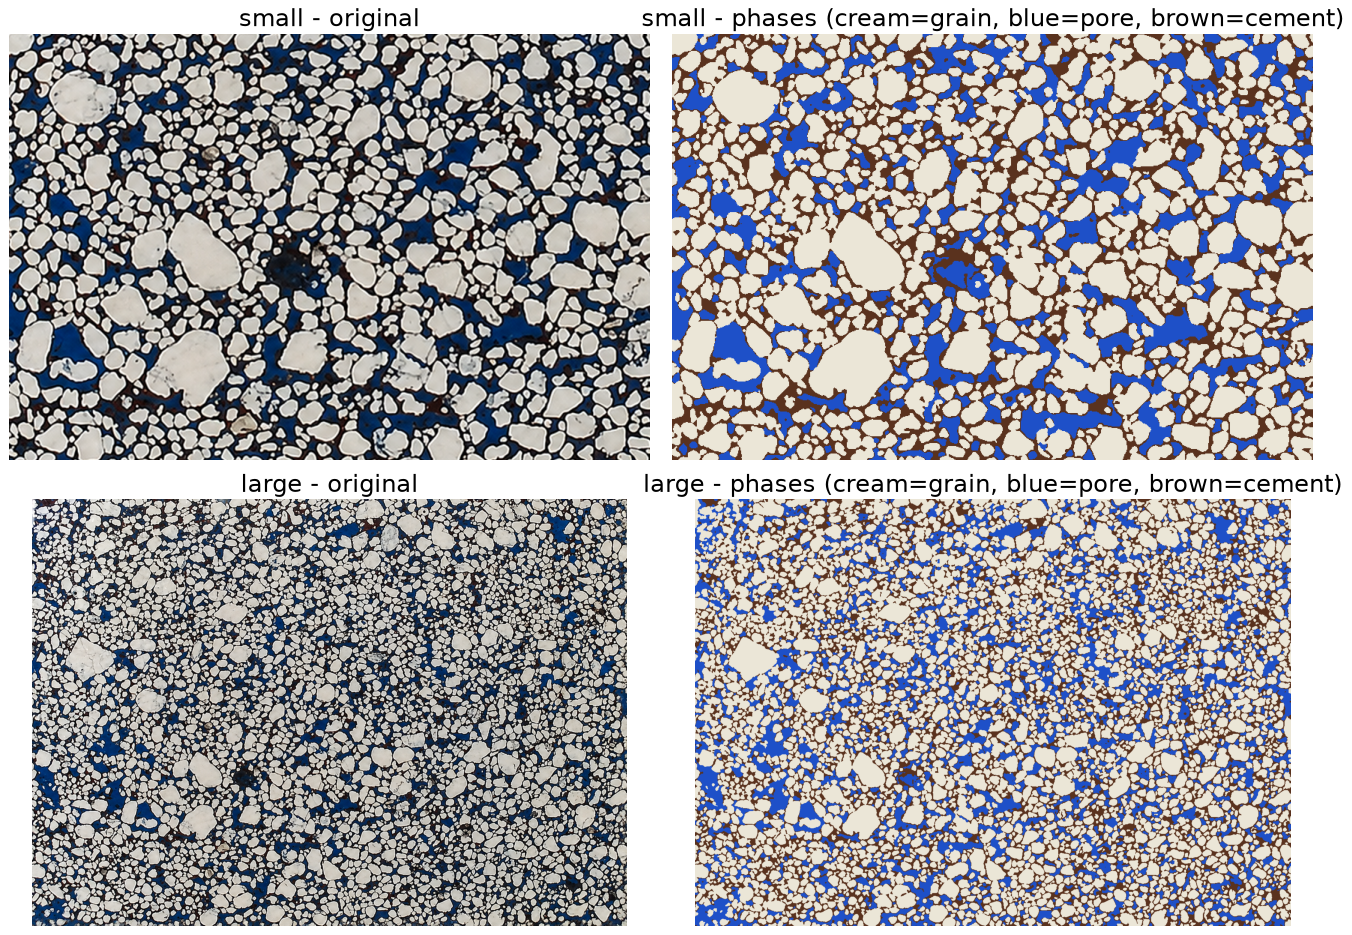

In [3]:
res = {k: three_phase(im) for k, im in imgs.items()}
for k, r in res.items():
    print(f'{k:6s} t_L = {r.t_L:.1f}')

fig, ax = plt.subplots(2, 2, figsize=(15, 10.5))
for i, (k, r) in enumerate(res.items()):
    ax[i, 0].imshow(imgs[k]); ax[i, 0].set_title(f'{k} - original'); ax[i, 0].axis('off')
    ax[i, 1].imshow(phase_rgb(r.phases)); ax[i, 1].set_title(f'{k} - phases (cream=grain, blue=pore, brown=cement)'); ax[i, 1].axis('off')
plt.tight_layout(); plt.show()

**Reading the result.** The Otsu threshold is almost the same in both images (47.6 and 48.5), so the rules behave
consistently. In the phase maps, the blue pores and the cream grains follow the original photos; every grain is
surrounded by a thin brown rim (the dark grain edges are counted as cement, see rule 4).

### Visual check on zoomed crops

**Why.** The whole-image maps are too small to see whether single pixels are classified correctly.

**What.** Three zoomed areas of the small image, each shown as the original photo (left) and its phase map (right).
They contain the difficult cases: dark blue pores, brown cement and thin gaps between grains.

**How to check.** Every blue area of the photo should be blue in the map, every brown/black area brown, and every
grain cream.

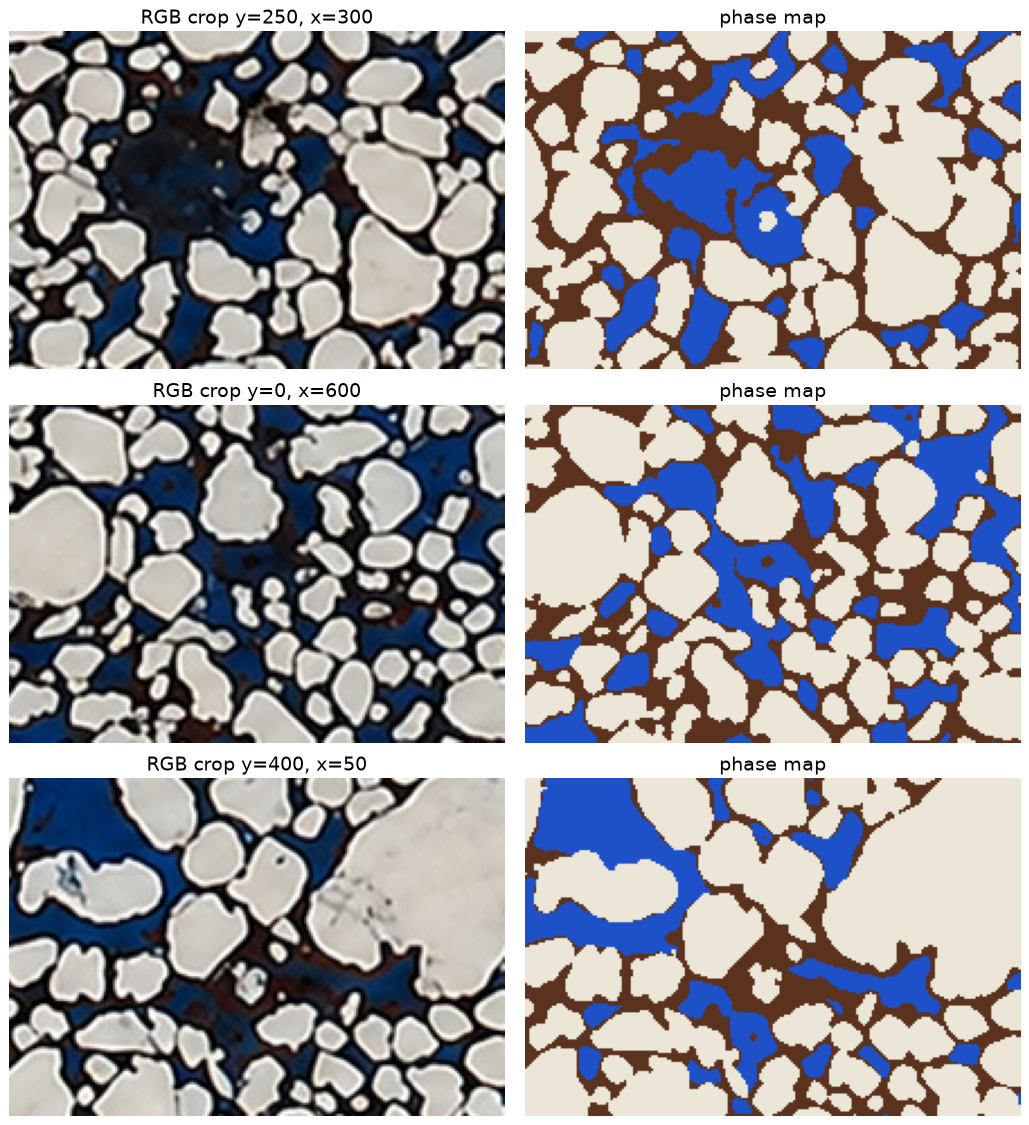

In [4]:
im, r = imgs['small'], res['small']
crops = [(250, 300), (0, 600), (400, 50)]
fig, ax = plt.subplots(len(crops), 2, figsize=(12, 4.2 * len(crops)))
for i, (y, x) in enumerate(crops):
    sl = (slice(y, y + 150), slice(x, x + 220))
    ax[i, 0].imshow(im[sl]); ax[i, 0].set_title(f'RGB crop y={y}, x={x}')
    ax[i, 1].imshow(phase_rgb(r.phases)[sl]); ax[i, 1].set_title('phase map')
    for a_ in ax[i]: a_.axis('off')
plt.tight_layout(); plt.show()

**Reading the result.** Grains and bright blue pores are classified correctly. The darkest blue pores are the hardest
case: most are recovered as pore by the hue rule, but their darkest cores can still go to cement. This is the main
source of porosity uncertainty, quantified in section 4.

## 3. Phase fractions (Task 1: porosity, grain and cement volume)

**The question.** This is Task 1 of the exercise: the volume of pores (porosity), grains and cement.

**Why it matters.** This section **measures the volume of pores, grains and cement**: Task 1 of the exercise. It is useful because:

1. **It answers Task 1 directly** (porosity, grain and cement volume).
2. **Porosity is the key reservoir property**: the volume available to store oil, gas or water.
3. **Grain and cement fractions describe the rock**: how much of the original pore space has been filled by cement.
4. **Both images are compared**, a first check of consistency.

**How.** Count the pixels of each phase in the phase map and divide by the total number of pixels. In a thin
section, the **area fraction equals the volume fraction** of the rock (Delesse principle), so these percentages are
the volume percentages.

In [5]:
rows = []
for k in imgs:
    rows.append({'image': k, **{f'{n} %': 100 * v for n, v in res[k].fractions.items()}})
frac = pd.DataFrame(rows).set_index('image').round(2)
frac

,cement %,grain %,pore %
image,,,
small,23.24,57.77,18.99
large,24.34,57.09,18.57


**Reading the table.** Small image: grain 57.8 %, pore 19.0 %, cement 23.2 %. Large image: 57.1 %, 18.6 %, 24.3 %.
The two images agree within ~ 1 point. The small differences are real variation (the large image covers more rock),
as checked in notebook 03.

## 4. Sensitivity of porosity to the pore rule

**The question.** Porosity depends on how much of the *dark navy* epoxy is counted as pore. We scan the chroma cut-off and compare
with the simple b\* < Otsu rule. This uncertainty must be reported with the result. The chroma limit (rule 3) is a
judgement, so its effect must be known.

**Why it matters.** This section measures **how much the porosity depends on the choice of the pore rule**. It is useful because:

1. **A result without its uncertainty is incomplete.** The chroma limit is a judgement; its effect on porosity must be known and reported.
2. **It compares with the first approach** (b* threshold), showing how much porosity the dark blue pores add.
3. **It gives the porosity range** reported in the conclusions (~ 16-19 %).

**What.** Porosity computed with the simple b\* < Otsu rule (the first approach) and with the hue rule for several
chroma limits, for both images. Then the same zoomed area with three of these rules.

**How.** `three_phase()` is re-run with `pore_rule='b'` or a different `min_chroma`; everything else is unchanged.

In [6]:
rows = []
for k, im in imgs.items():
    rows.append({'image': k, 'rule': 'b* < Otsu', 'porosity %': 100 * three_phase(im, pore_rule='b').fractions['pore']})
    for c in [3, 4, 5, 6, 8, 10]:
        rows.append({'image': k, 'rule': f'hue, chroma > {c}',
                     'porosity %': 100 * three_phase(im, min_chroma=c).fractions['pore']})
sens = pd.DataFrame(rows).pivot(index='rule', columns='image', values='porosity %').round(2)
sens

image,large,small
rule,,
b* < Otsu,11.53,12.19
"hue, chroma > 10",13.60,14.33
"hue, chroma > 3",21.38,21.64
"hue, chroma > 4",19.91,20.25
"hue, chroma > 5",18.57,18.99
"hue, chroma > 6",17.37,17.85
"hue, chroma > 8",15.32,15.91


**Reading the table.** Porosity is ~ 12 % with the b\* rule and 14-22 % with the hue rule, depending on the chroma
limit (C > 3: 21.6 %, C > 5: 19.0 %, C > 8: 15.9 %, C > 10: 14.3 %; small image). Both images follow the same
pattern. The chroma limit is therefore the **main uncertainty** in porosity.

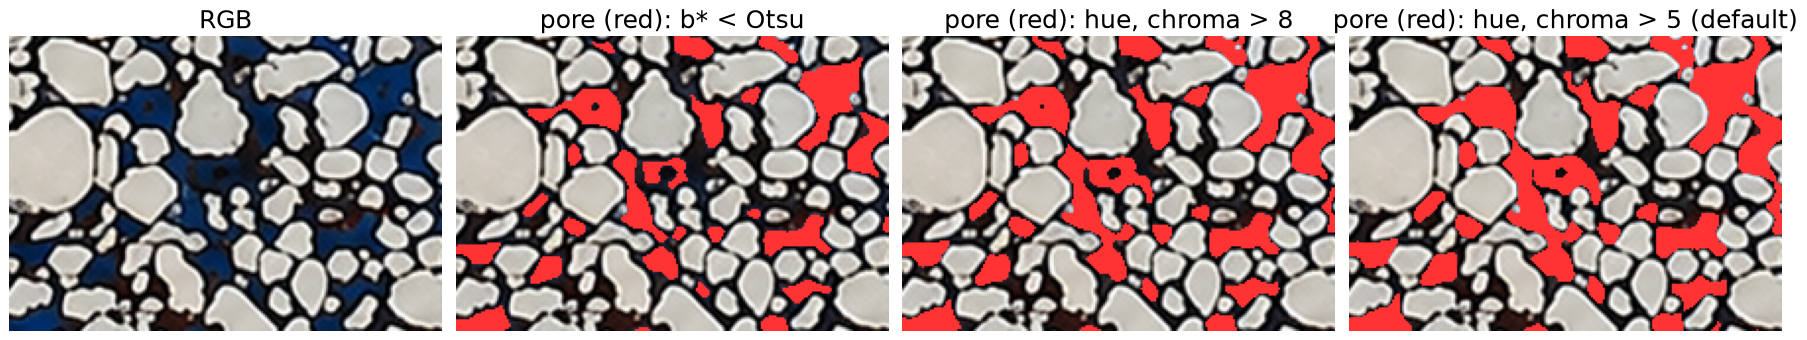

In [7]:
im, r = imgs['small'], res['small']
sl = (slice(0, 150), slice(600, 820))
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
ax[0].imshow(im[sl]); ax[0].set_title('RGB')
for a_, (lbl, kw) in zip(ax[1:], [('b* < Otsu', dict(pore_rule='b')), ('hue, chroma > 8', dict(min_chroma=8)),
                                  ('hue, chroma > 5 (default)', dict())]):
    p = three_phase(im, **kw).phases[sl] == PORE
    o = im[sl].copy(); o[p] = [1, 0.2, 0.2]
    a_.imshow(o); a_.set_title(f'pore (red): {lbl}')
for a_ in ax: a_.axis('off')
plt.tight_layout(); plt.show()

**Reading the result.** The b\* rule misses most of the dark navy epoxy. C > 8 recovers more, and C > 5 (our default)
matches the visible blue best. Reported porosity: **~ 19 %, with a plausible range of ~ 16-19 %**.

## 5. Save outputs for the next notebooks

**What is saved** (in `outputs/`):
- `phases_small.npy`, `phases_large.npy`: the phase maps (0 = cement, 1 = grain, 2 = pore), used by notebooks 02-05;
- `phases_small.png`, `phases_large.png`: the same maps as color images;
- `01_phase_fractions.csv`: the table of section 3;
- `01_porosity_sensitivity.csv`: the table of section 4.

In [8]:
import os
os.makedirs('../outputs', exist_ok=True)
for k, r in res.items():
    np.save(f'../outputs/phases_{k}.npy', r.phases)
    plt.imsave(f'../outputs/phases_{k}.png', phase_rgb(r.phases))
frac.to_csv('../outputs/01_phase_fractions.csv')
sens.to_csv('../outputs/01_porosity_sensitivity.csv')
print(os.listdir('../outputs'))

['01_phase_fractions.csv', '01_porosity_sensitivity.csv', '02_objects.csv', '02_object_counts.csv', '02_split_sensitivity.csv', '03_folk_ward.csv', '03_objects_scaled.csv', '03_phase_areas.csv', '03_registration.csv', '03_throats.csv', '04_blocks.csv', '04_block_spearman.csv', '04_clark_evans.csv', '04_correlation_functions.csv', '04_correlation_lengths.csv', '04_integral_range.csv', '04_porosity_map_128.npy', '04_rev_random_windows.csv', '04_rev_sizes.csv', '05_efd_coefficients.csv', '05_grain_shape.csv', '05_harmonic_amplitudes.csv', '05_radial_signatures.csv', '05_shape_families.csv', '05_shape_moran.csv', 'figures', 'labels_grain_large.npy', 'labels_grain_small.npy', 'labels_pore_large.npy', 'labels_pore_small.npy', 'phases_large.npy', 'phases_large.png', 'phases_small.npy', 'phases_small.png']


## Findings

- The **Lab color space** separates the three phases. Grayscale cannot, because pore and cement are both dark.
- Grain fraction is **stable (~ 57-58 %)** in both images and does not depend on the pore rule.
- **Porosity (blue epoxy) is the most uncertain quantity.** It ranges from ~ 12 % (strict b\* rule) to ~ 21 % (hue rule, chroma > 3). The reported value is ~ 19 % (chroma > 5),
  with a plausible range of ~ 16-19 % for chroma limits 5-8 (section 4).
  The difference is the dark navy epoxy in thicker or shadowed areas. The hue rule (chroma > 5) matches the visible
  blue best, so it is our default. The range is reported as the uncertainty.
- The thin black rim around every grain is classified as cement. It is partly a real coating/cement and partly an optical
  edge effect, so the cement fraction is an **upper bound**.
- The dark stain near the center of the slide (epoxy with a dark tint) is mostly recovered as pore by the hue rule, but its darkest core still goes to cement.
- The small and large images give consistent fractions, which is a first indication that both are larger than the porosity REV (checked in notebook 04).